# Retail Sales Forecasting

This project explores forecasting transaction value from the UCI Online
Retail dataset. We will use a chronological holdout and compare simple
forecasting baselines.

The dataset covers about one year. December 2011 is incomplete, so the
short history limits the conclusions we can draw.

In [8]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "raw" / "Online Retail.xlsx"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_raw = pd.read_excel(
    DATA_PATH,
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "CustomerID": "string",
    },
)

print(f"Rows: {len(df_raw):,}")
print(f"Columns: {len(df_raw.columns)}")
print(f"First transaction: {df_raw['InvoiceDate'].min()}")
print(f"Last transaction: {df_raw['InvoiceDate'].max()}")

display(df_raw.head())

Rows: 541,909
Columns: 8
First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [9]:
print("Missing values:")
display(
    df_raw.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print(f"Exact duplicate candidates: {df_raw.duplicated().sum():,}")

monthly_coverage = (
    df_raw.assign(
        month=df_raw["InvoiceDate"].dt.to_period("M"),
        date=df_raw["InvoiceDate"].dt.date,
    )
    .groupby("month")
    .agg(
        transaction_lines=("InvoiceNo", "size"),
        observed_dates=("date", "nunique"),
        first_record=("InvoiceDate", "min"),
        last_record=("InvoiceDate", "max"),
    )
)

display(monthly_coverage)

Missing values:


,missing_count
CustomerID,135080
Description,1454
InvoiceNo,0
StockCode,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Exact duplicate candidates: 5,268


,transaction_lines,observed_dates,first_record,last_record
month,,,,
2010-12,42481,20,2010-12-01 08:26:00,2010-12-23 17:41:00
2011-01,35147,24,2011-01-04 10:00:00,2011-01-31 16:59:00
2011-02,27707,24,2011-02-01 08:23:00,2011-02-28 17:04:00
2011-03,36748,27,2011-03-01 08:30:00,2011-03-31 19:55:00
2011-04,29916,21,2011-04-01 08:22:00,2011-04-28 19:53:00
2011-05,37030,25,2011-05-01 10:51:00,2011-05-31 15:53:00
2011-06,36874,26,2011-06-01 07:37:00,2011-06-30 20:08:00
2011-07,39518,26,2011-07-01 08:16:00,2011-07-31 16:04:00
2011-08,35284,26,2011-08-01 08:30:00,2011-08-31 17:45:00


## Forecast Target and Evaluation Plan

- Target: monthly signed transaction value in GBP, calculated as
  Quantity × UnitPrice for records with a positive unit price.
- Negative quantities are included in their recorded month.
- Exact duplicate candidates are retained.
- December 2011 is excluded because it is incomplete.
- December 2010 through November 2011 provides 12 calendar months.
- The final three complete months, September–November 2011, are held
  out for final evaluation. The earlier nine months are training data.

Twelve months are insufficient to establish yearly seasonality or
reliable long-term forecasting performance.

Training months: 2010-12 to 2011-08
Test months: 2011-09 to 2011-11


,signed_transaction_value
month,
2010-12-01,748957.02
2011-01-01,560000.26
2011-02-01,498062.65
2011-03-01,683267.08
2011-04-01,493207.12
2011-05-01,723333.51
2011-06-01,691123.12
2011-07-01,681300.11
2011-08-01,704804.63


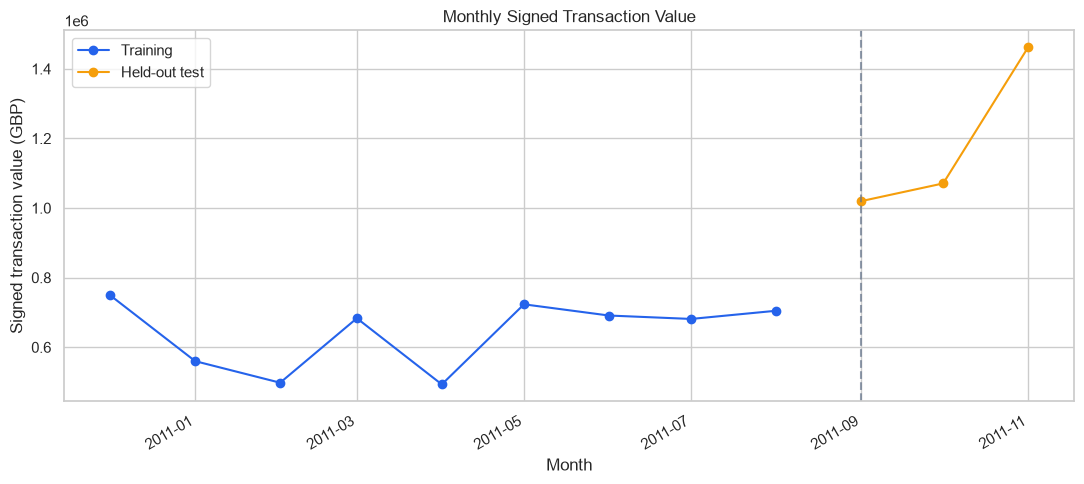

In [10]:
import matplotlib.dates as mdates

# Create a copy and calculate signed transaction value.
forecast_data = df_raw.loc[df_raw["UnitPrice"] > 0].copy()

forecast_data["signed_value"] = (
    forecast_data["Quantity"] * forecast_data["UnitPrice"]
)

forecast_data["month"] = (
    forecast_data["InvoiceDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Use the 12 complete calendar months in the dataset.
start_month = pd.Timestamp("2010-12-01")
end_month = pd.Timestamp("2011-11-01")

expected_months = pd.date_range(
    start=start_month,
    end=end_month,
    freq="MS",
)

monthly = (
    forecast_data.groupby("month")["signed_value"]
    .sum()
    .reindex(expected_months)
    .rename("signed_transaction_value")
)

if monthly.isna().any():
    raise ValueError(
        "At least one expected month has no qualifying records. "
        "Inspect the coverage before forecasting."
    )

monthly.index.name = "month"

# Final holdout: September, October, and November 2011.
train = monthly.loc[:"2011-08-01"]
test = monthly.loc["2011-09-01":"2011-11-01"]

assert len(train) == 9
assert len(test) == 3

print(
    f"Training months: {train.index.min():%Y-%m} "
    f"to {train.index.max():%Y-%m}"
)
print(
    f"Test months: {test.index.min():%Y-%m} "
    f"to {test.index.max():%Y-%m}"
)

display(monthly.round(2).to_frame())

# Plot training and held-out values.
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    train.index,
    train.to_numpy(dtype=float),
    marker="o",
    label="Training",
    color="#2563eb",
)

ax.plot(
    test.index,
    test.to_numpy(dtype=float),
    marker="o",
    label="Held-out test",
    color="#f59e0b",
)

# Mark the start of the held-out test period.
boundary_number = float(
    mdates.date2num(
        pd.Timestamp("2011-09-01").to_pydatetime()
    )
)

ax.axvline(
    boundary_number,
    color="#64748b",
    linestyle="--",
    alpha=0.7,
)

ax.set_title("Monthly Signed Transaction Value")
ax.set_xlabel("Month")
ax.set_ylabel("Signed transaction value (GBP)")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Baseline Validation

Each validation forecast predicts three months using only earlier
training observations. We compare mean absolute error (MAE), in GBP.

The validation windows overlap, and the history is very short. These
results are exploratory; the final September–November test remains
untouched during model selection.

In [11]:
from sklearn.metrics import mean_absolute_error

horizon = 3
min_history = 3

validation_rows = []

# Use only the nine training months for these validation windows.
for history_end in range(
    min_history,
    len(train) - horizon + 1,
):
    history = train.iloc[:history_end]
    actual = train.iloc[history_end:history_end + horizon]

    forecasts = {
        "Last month": np.repeat(history.iloc[-1], horizon),
        "Historical average": np.repeat(history.mean(), horizon),
    }

    for model_name, predictions in forecasts.items():
        for month, actual_value, predicted_value in zip(
            actual.index,
            actual.values,
            predictions,
        ):
            validation_rows.append({
                "model": model_name,
                "forecast_origin": history.index[-1],
                "month": month,
                "actual": actual_value,
                "prediction": predicted_value,
                "absolute_error": abs(actual_value - predicted_value),
            })

validation_results = pd.DataFrame(validation_rows)

validation_summary = (
    validation_results.groupby("model")
    .agg(
        validation_forecasts=("absolute_error", "size"),
        mae_gbp=("absolute_error", "mean"),
    )
    .sort_values("mae_gbp")
)

print("Rolling validation results:")
display(validation_summary.round(2))

print("Individual validation forecasts:")
display(validation_results.round(2))

selected_baseline = validation_summary.index[0]
print(f"Selected baseline: {selected_baseline}")

Rolling validation results:


,validation_forecasts,mae_gbp
model,,
Historical average,12,94933.80
Last month,12,113518.44


Individual validation forecasts:


/var/folders/_8/8rdsbpj16tnc6j516ntvn4h40000gn/T/ipykernel_1870/514428593.py:51: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(validation_results.round(2))


,model,forecast_origin,month,actual,prediction,absolute_error
0,Last month,2011-02-01,2011-03-01,683267.08,498062.65,185204.43
1,Last month,2011-02-01,2011-04-01,493207.12,498062.65,4855.53
2,Last month,2011-02-01,2011-05-01,723333.51,498062.65,225270.86
3,Historical average,2011-02-01,2011-03-01,683267.08,602339.98,80927.10
4,Historical average,2011-02-01,2011-04-01,493207.12,602339.98,109132.86
5,Historical average,2011-02-01,2011-05-01,723333.51,602339.98,120993.53
6,Last month,2011-03-01,2011-04-01,493207.12,683267.08,190059.96
7,Last month,2011-03-01,2011-05-01,723333.51,683267.08,40066.43
8,Last month,2011-03-01,2011-06-01,691123.12,683267.08,7856.04
9,Historical average,2011-03-01,2011-04-01,493207.12,622571.75,129364.63


Selected baseline: Historical average


## Final Holdout Evaluation

The selected baseline is fitted using all nine training months.
It produces a fixed three-month forecast without using holdout values.

MAE is the average absolute difference between forecasts and actual
monthly values. Three months provide only a limited evaluation.

Selected baseline: Historical average
Test MAE: £541,376.68
Test RMSE: £576,266.44


,actual,forecast,absolute_error
month,,,
2011-09-01,1019687.62,642672.83,377014.79
2011-10-01,1070704.67,642672.83,428031.84
2011-11-01,1461756.25,642672.83,819083.42


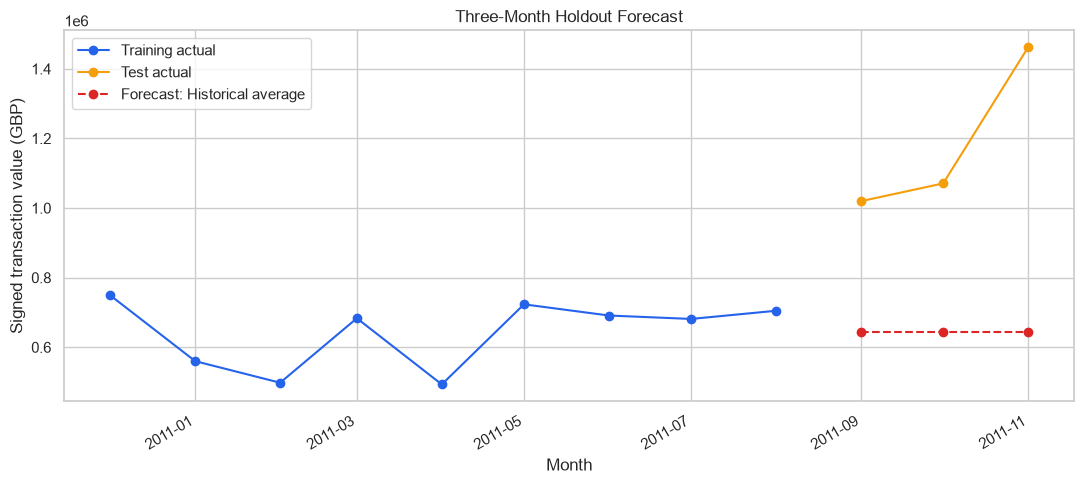

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Produce all three forecasts using only the training period.
if selected_baseline == "Last month":
    forecast_value = train.iloc[-1]
elif selected_baseline == "Historical average":
    forecast_value = train.mean()
else:
    raise ValueError(f"Unknown baseline: {selected_baseline}")

test_forecast = pd.Series(
    forecast_value,
    index=test.index,
    name="forecast",
)

test_comparison = pd.DataFrame({
    "actual": test,
    "forecast": test_forecast,
})

test_comparison["absolute_error"] = (
    test_comparison["actual"] - test_comparison["forecast"]
).abs()

mae = mean_absolute_error(test, test_forecast)
rmse = np.sqrt(mean_squared_error(test, test_forecast))

print(f"Selected baseline: {selected_baseline}")
print(f"Test MAE: £{mae:,.2f}")
print(f"Test RMSE: £{rmse:,.2f}")
display(test_comparison.round(2))

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    train.index,
   train.to_numpy(dtype=float),
    marker="o",
    label="Training actual",
    color="#2563eb",
)

ax.plot(
    test.index,
    test.to_numpy(dtype=float),
    marker="o",
    label="Test actual",
    color="#f59e0b",
)

ax.plot(
    test_forecast.index,
    test_forecast.to_numpy(dtype=float),
    marker="o",
    linestyle="--",
    label=f"Forecast: {selected_baseline}",
    color="#dc2626",
)

ax.set_title("Three-Month Holdout Forecast")
ax.set_xlabel("Month")
ax.set_ylabel("Signed transaction value (GBP)")
ax.legend()

fig.autofmt_xdate()
fig.tight_layout()

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES / "baseline_holdout.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Exploratory Linear Trend

Fit a straight-line trend using only observations available at each
validation origin, then forecast the next three months.

This is exploratory because the holdout results have already been
viewed. With only nine training months, trend estimates are unstable.

In [13]:
from sklearn.linear_model import LinearRegression

trend_rows = []

for history_end in range(
    min_history,
    len(train) - horizon + 1,
):
    history = train.iloc[:history_end]
    actual = train.iloc[history_end:history_end + horizon]

    X_history = np.arange(len(history)).reshape(-1, 1)
    X_future = np.arange(
        len(history),
        len(history) + horizon,
    ).reshape(-1, 1)

    trend_model = LinearRegression()
    trend_model.fit(X_history, history.to_numpy(dtype=float))
    predictions = trend_model.predict(X_future)

    for month, actual_value, predicted_value in zip(
        actual.index,
        actual.to_numpy(dtype=float),
        predictions,
    ):
        trend_rows.append({
            "model": "Linear trend",
            "forecast_origin": history.index[-1],
            "month": month,
            "actual": actual_value,
            "prediction": predicted_value,
            "absolute_error": abs(actual_value - predicted_value),
        })

trend_validation = pd.DataFrame(trend_rows)

all_validation = pd.concat(
    [validation_results, trend_validation],
    ignore_index=True,
)

all_validation_summary = (
    all_validation.groupby("model")
    .agg(
        validation_forecasts=("absolute_error", "size"),
        mae_gbp=("absolute_error", "mean"),
    )
    .sort_values("mae_gbp")
)

print("Exploratory rolling validation comparison:")
display(all_validation_summary.round(2))

Exploratory rolling validation comparison:


,validation_forecasts,mae_gbp
model,,
Historical average,12,94933.80
Last month,12,113518.44
Linear trend,12,226130.68


In [14]:
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

# Save validation forecasts and summaries.
all_validation.to_csv(
    REPORTS / "rolling_validation_forecasts.csv",
    index=False,
)

all_validation_summary.to_csv(
    REPORTS / "rolling_validation_summary.csv"
)

# Save the baseline holdout evaluation.
test_comparison.to_csv(
    REPORTS / "baseline_holdout_forecasts.csv"
)

holdout_metrics = pd.DataFrame([{
    "selected_baseline": selected_baseline,
    "mae_gbp": mae,
    "rmse_gbp": rmse,
    "test_months": len(test),
}])

holdout_metrics.to_csv(
    REPORTS / "baseline_holdout_metrics.csv",
    index=False,
)

print("Best exploratory validation model:", all_validation_summary.index[0])
print(
    "Best validation MAE:",
    f"£{all_validation_summary.iloc[0]['mae_gbp']:,.2f}",
)
print("Previously selected baseline:", selected_baseline)
print(f"Baseline holdout MAE: £{mae:,.2f}")
print(f"Baseline holdout RMSE: £{rmse:,.2f}")
print(f"\nReports saved in: {REPORTS}")

Best exploratory validation model: Historical average
Best validation MAE: £94,933.80
Previously selected baseline: Historical average
Baseline holdout MAE: £541,376.68
Baseline holdout RMSE: £576,266.44

Reports saved in: /Users/rashmidragon/Desktop/retail-sales-forecasting/reports


## Findings and Limitations

- The forecast target is monthly signed transaction value, including
  negative-quantity records and charges with positive unit prices.
- The baseline was selected through rolling validation on the training
  period and evaluated on September–November 2011.
- The linear-trend comparison is exploratory because the holdout
  results were already viewed.
- Validation windows overlap, and only three months are in the holdout.
- The dataset contains only 12 complete months, so it is too short to
  establish annual seasonality or reliable long-term performance.
- Negative entries are recorded in their transaction month; they are
  not necessarily matched to the original sale.
- The dataset describes one historical retailer. Forecast accuracy
  may not generalize to future periods or other businesses.